# Room Occupancy Estimation — Notebook 01: Data Exploration

**Course:** AIML ZG565 Machine Learning — Assignment 2
**Dataset:** Room Occupancy Estimation, UCI Machine Learning Repository (id 864)
**Goal:** understand the data before modelling — size, columns, data quality, class balance.

In [2]:
# Imports
import pandas as pd                 # tables (DataFrames)

# Path to the data: "../" goes up from notebooks/ to the project folder
DATA_PATH = "../data/Occupancy_Estimation.csv"

# Load the CSV and show its size and first rows
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 10,129   Columns: 19


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1


## 1. Columns and their meaning

| Group | Columns | Unit / values | Meaning |
|---|---|---|---|
| Time stamp | Date, Time | text | when the reading was taken (every ~30 s) |
| Temperature | S1_Temp … S4_Temp | °C | temperature at 4 sensor nodes |
| Light | S1_Light … S4_Light | lux | light level at 4 nodes |
| Sound | S1_Sound … S4_Sound | volts | noise level at 4 nodes |
| CO2 | S5_CO2 | ppm | carbon dioxide (people breathe it out) |
| CO2 slope | S5_CO2_Slope | ppm change | how fast CO2 is rising or falling |
| Motion | S6_PIR, S7_PIR | 0 / 1 | motion detected by infrared sensors |
| **Target** | **Room_Occupancy_Count** | 0, 1, 2, 3 | number of people in the room |

**Decision:** drop `Date` and `Time` — they record *when* a reading was taken, not *what* the
sensors measured. A model using them would memorise the experiment schedule instead of learning
from the sensors.

In [3]:
# Data type of every column
print(df.dtypes)

# Target column and the columns we will drop
TARGET = "Room_Occupancy_Count"
DROP_COLS = ["Date", "Time"]

# Features = every column except the dropped ones and the target
features = [c for c in df.columns if c not in DROP_COLS + [TARGET]]

print(f"\nNumber of features: {len(features)}")
print(features)

Date                        str
Time                        str
S1_Temp                 float64
S2_Temp                 float64
S3_Temp                 float64
S4_Temp                 float64
S1_Light                  int64
S2_Light                  int64
S3_Light                  int64
S4_Light                  int64
S1_Sound                float64
S2_Sound                float64
S3_Sound                float64
S4_Sound                float64
S5_CO2                    int64
S5_CO2_Slope            float64
S6_PIR                    int64
S7_PIR                    int64
Room_Occupancy_Count      int64
dtype: object

Number of features: 16
['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']


## 2. Data quality — missing values and duplicates

In [4]:
# Missing values anywhere in the table
print("Missing values in the whole table:", df.isna().sum().sum())

# Duplicate rows, checked two ways
print("Duplicate rows (all 19 columns):  ", df.duplicated().sum())
print("Duplicate rows (features + target):", df[features + [TARGET]].duplicated().sum())

# Number of readings recorded on each day
df["Date"].value_counts().sort_index()

Missing values in the whole table: 0
Duplicate rows (all 19 columns):   0
Duplicate rows (features + target): 1301


Date
2017/12/22    1462
2017/12/23    2779
2017/12/24    1064
2017/12/25    1716
2017/12/26    1063
2018/01/10     997
2018/01/11    1048
Name: count, dtype: int64

**Findings**
- **No missing values** → no imputation needed.
- **No duplicate records** over all 19 columns (every reading has its own time stamp).
- **1,301 rows repeat the same sensor values** once Date/Time are ignored. All of them are
  empty-room readings, mostly at night, when every sensor stays constant. They are genuine
  repeated situations, so we **keep them**.
- Data covers **7 days** (22–26 Dec 2017, 10–11 Jan 2018).

## 3. Target distribution — is the data balanced?

Matplotlib is building the font cache; this may take a moment.


                rows  percent
people in room               
0               8228     81.2
1                459      4.5
2                748      7.4
3                694      6.9

Imbalance ratio (largest / smallest class): 17.9 : 1


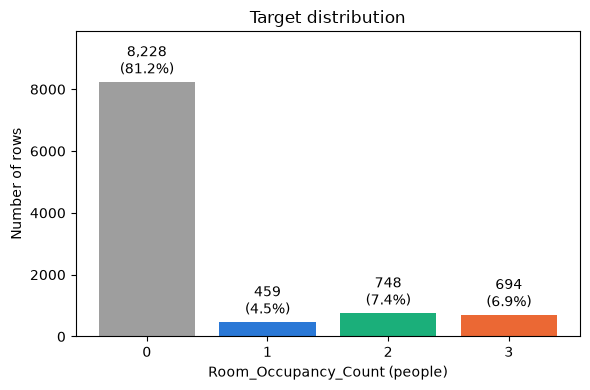

In [5]:
import matplotlib.pyplot as plt     # plotting

# Number and percentage of rows for 0, 1, 2 and 3 people
counts = df[TARGET].value_counts().sort_index()
dist = pd.DataFrame({"rows": counts,
                     "percent": (counts / len(df) * 100).round(1)})
dist.index.name = "people in room"
print(dist)
print(f"\nImbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f} : 1")

# Bar chart with count and percentage on each bar
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(dist.index.astype(str), dist["rows"],
              color=["#9e9e9e", "#2a78d6", "#1baf7a", "#eb6834"])
ax.bar_label(bars, labels=[f"{r:,}\n({p}%)" for r, p in zip(dist["rows"], dist["percent"])],
             padding=3)
ax.set_xlabel("Room_Occupancy_Count (people)")
ax.set_ylabel("Number of rows")
ax.set_title("Target distribution")
ax.set_ylim(0, counts.max() * 1.2)      # space above the bars for the labels
plt.tight_layout()
plt.show()

**Findings — strongly imbalanced (81% "empty room", ratio 17.9 : 1)**
- Always predicting "0 people" would already give 81% accuracy, so **accuracy alone is misleading**.
- Plan for Notebook 02:
  1. **Stratified** train/test split, so classes 1, 2, 3 keep their share in the test set.
  2. **Macro-averaged** Precision, Recall and F1, so every class counts equally.
  3. **MCC** and **AUC**, which are not fooled by the majority class.

## 4. Feature scales

In [6]:
# Mean, spread, min, max and range of every feature
summary = df[features].describe().T[["mean", "std", "min", "max"]].round(2)
summary["range"] = (summary["max"] - summary["min"]).round(2)
summary

,mean,std,min,max,range
S1_Temp,25.45,0.35,24.94,26.38,1.44
S2_Temp,25.55,0.59,24.75,29.00,4.25
S3_Temp,25.06,0.43,24.44,26.19,1.75
S4_Temp,25.75,0.36,24.94,26.56,1.62
S1_Light,25.45,51.01,0.00,165.00,165.00
S2_Light,26.02,67.30,0.00,258.00,258.00
S3_Light,34.25,58.40,0.00,280.00,280.00
S4_Light,13.22,19.60,0.00,74.00,74.00
S1_Sound,0.17,0.32,0.06,3.88,3.82
S2_Sound,0.12,0.27,0.04,3.44,3.40


**Findings — very different scales**
- CO2 ranges over ~925 ppm and light over up to 280 lux, while temperature changes by only ~1.5–4 °C
  and the motion sensors are 0/1.
- **Logistic Regression, KNN and SVM** use distances or weighted sums, so large-range features would
  dominate → we will **standardise** (z-score) the features for these models.
- **Decision Tree** and **Gaussian Naive Bayes** treat each feature separately and don't need scaling;
  we still use the same "scaler + model" pipeline for all five models for consistency.
- `S5_CO2_Slope` has negative values, so we use **Gaussian** (not Multinomial) Naive Bayes.

## 5. Which sensors change with occupancy?

In [7]:
# Average value of every feature for 0, 1, 2 and 3 people
group_means = df.groupby(TARGET)[features].mean().T.round(2)
group_means

Room_Occupancy_Count,0,1,2,3
S1_Temp,25.34,25.74,26.00,26.07
S2_Temp,25.37,25.83,26.21,26.72
S3_Temp,24.93,25.30,25.59,25.83
S4_Temp,25.66,26.09,26.18,26.19
S1_Light,2.69,120.21,136.11,113.32
S2_Light,3.05,31.43,134.80,177.43
S3_Light,13.37,54.23,138.34,156.39
S4_Light,9.23,37.58,30.48,25.76
S1_Sound,0.08,0.44,0.64,0.56
S2_Sound,0.05,0.14,0.53,0.47


**Findings (average reading per class)**
- **Light** is the clearest signal: ~0–13 lux when empty, 100+ lux when occupied.
- **CO2** rises steadily with people (404 → 471 → 713 → 851 ppm) and the **CO2 slope** turns from
  negative to strongly positive → useful to tell 1, 2 and 3 people apart.
- **Motion (PIR)** is exactly 0 in an empty room.
- **Temperature** and **sound** increase with occupancy, but only slightly.
- **S4_Light** peaks at 1 person and then falls → not every sensor grows steadily with occupancy
  (a non-linear pattern).
- Separating **empty vs occupied** looks easy; separating **1 vs 2 vs 3 people** is the harder task.

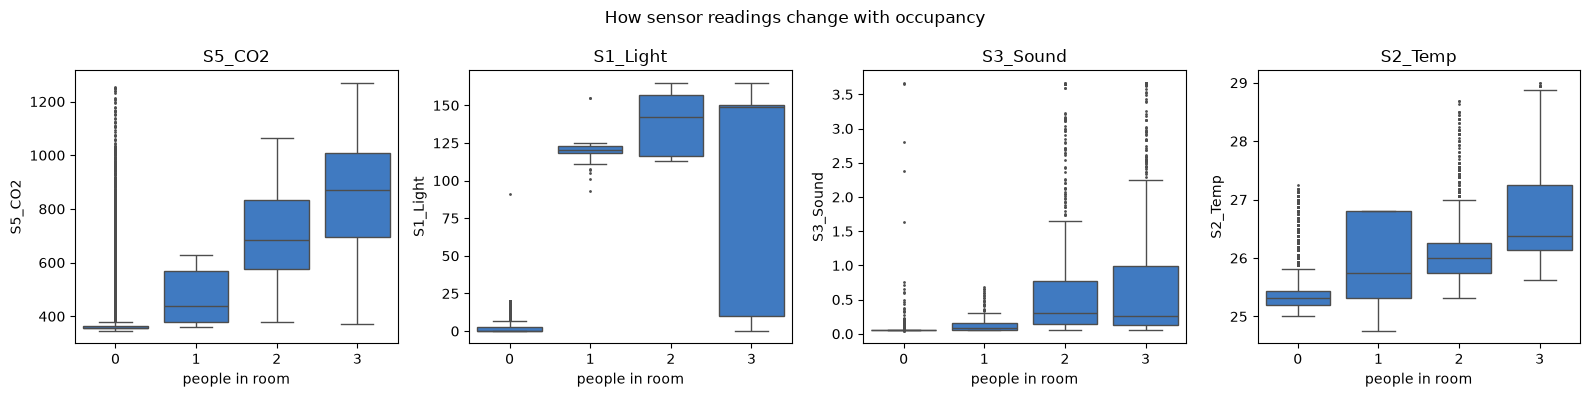

In [8]:
import seaborn as sns               # statistical plots

# Box plots of 4 representative sensors for each class
show = ["S5_CO2", "S1_Light", "S3_Sound", "S2_Temp"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, show):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, color="#2a78d6", fliersize=1)
    ax.set_title(col)
    ax.set_xlabel("people in room")
plt.suptitle("How sensor readings change with occupancy")
plt.tight_layout()
plt.show()

**Findings (box plots)**
- **CO2** stays high for a while **after people leave** (long tail of high values for 0 people) →
  CO2 alone can confuse "recently empty" with "occupied".
- **Light** separates empty vs occupied very well, but for 3 people S1_Light ranges from ~10 to 150
  (people may sit away from that sensor) → classes 2 and 3 overlap.
- **Sound** is bursty (talking comes and goes) → many spikes, a noisy signal on its own.
- **Temperature** rises slowly; classes 1–3 overlap heavily.
- No single sensor separates all 4 classes → the models must **combine** sensors.

In [9]:
# Share of rows with each motion combination (S6_PIR, S7_PIR), for each class
# normalize="index" -> each row adds up to 1 (i.e. percentages within each class)
pd.crosstab(df[TARGET], [df["S6_PIR"], df["S7_PIR"]], normalize="index").round(2)

S6_PIR                   0           1      
S7_PIR                   0     1     0     1
Room_Occupancy_Count                        
0                     1.00  0.00  0.00  0.00
1                     0.65  0.01  0.31  0.03
2                     0.36  0.16  0.21  0.27
3                     0.23  0.23  0.11  0.43

**Findings (motion sensors)**
- Motion **never** fires in an empty room → when PIR = 1, the room is definitely occupied.
- But **no motion ≠ empty**: 65% of 1-person readings show no motion (people sitting still).
- Both sensors firing together grows with the number of people (3% → 27% → 43%).
- So motion is a reliable "occupied" signal but must be combined with light and CO2 to count people.

## 6. Correlation between features

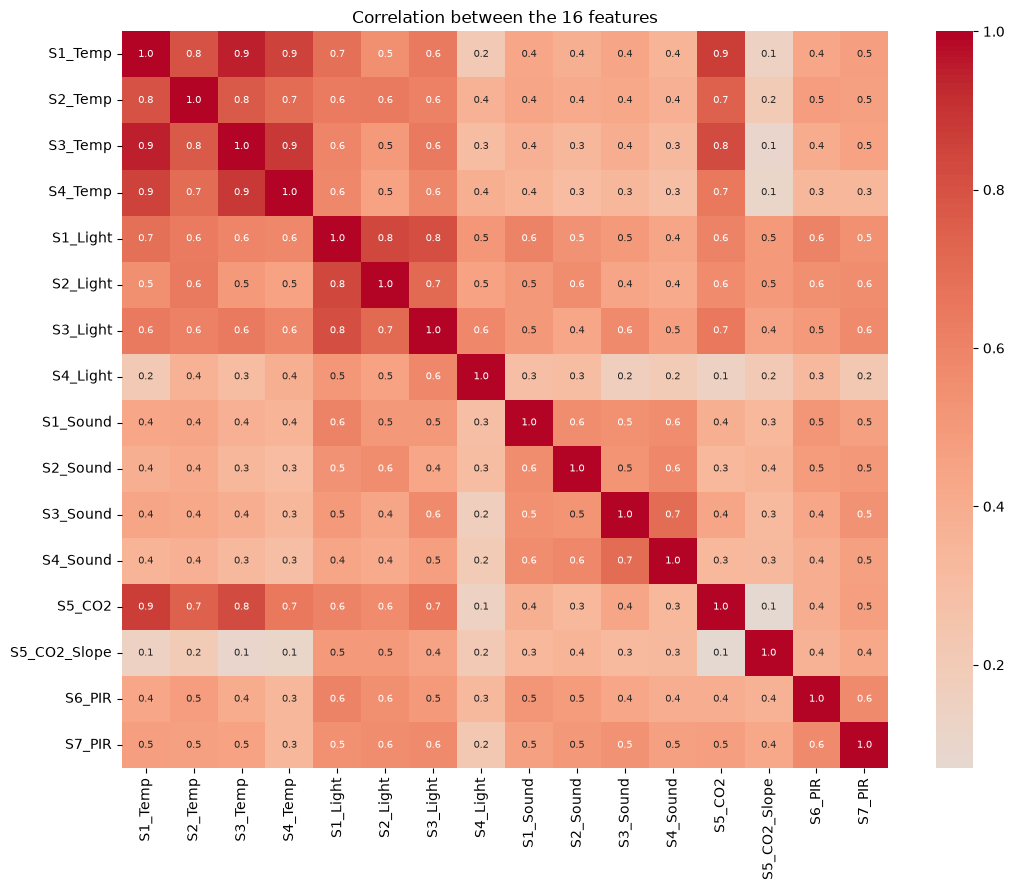

Most correlated feature pairs:
S1_Temp   S3_Temp     0.95
S3_Temp   S4_Temp     0.89
S1_Temp   S5_CO2      0.87
          S4_Temp     0.86
S1_Light  S2_Light    0.84
S3_Temp   S5_CO2      0.82
S1_Light  S3_Light    0.82
S1_Temp   S2_Temp     0.80
dtype: float64

Correlation with Room_Occupancy_Count:
S1_Light        0.85
S3_Light        0.79
S2_Light        0.79
S1_Temp         0.70
S7_PIR          0.70
S2_Temp         0.67
S5_CO2          0.66
S3_Temp         0.65
S6_PIR          0.63
S5_CO2_Slope    0.60
S1_Sound        0.57
S2_Sound        0.56
S3_Sound        0.53
S4_Temp         0.53
S4_Sound        0.46
S4_Light        0.36
Name: Room_Occupancy_Count, dtype: float64


In [10]:
import numpy as np                  # numeric helpers

# Correlation heat map of the 16 features
corr = df[features].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation between the 16 features")
plt.tight_layout()
plt.show()

# Most strongly correlated pairs (upper triangle only, so each pair appears once)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Most correlated feature pairs:")
print(pairs.sort_values(ascending=False).head(8).round(2))

# How strongly each feature moves with the target
print("\nCorrelation with Room_Occupancy_Count:")
print(df[features + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(2))

**Findings (correlation)**
- Sensors of the same type are **highly correlated**: the 4 temperatures (0.7–0.95) and the 3 main
  lights (0.7–0.8) measure the same room; CO2 and temperature also move together (0.87).
- **CO2 slope** and **S4_Light** are only weakly correlated with the rest → they add new information.
- Light is most related to occupancy (S1_Light 0.85); S4_Light the least (0.36).
- **Naive Bayes** assumes independent features, so correlated sensors are "counted twice" → we expect
  it to perform worst. We keep all 16 features (assignment needs ≥ 12; other models handle the overlap).

## 7. Summary and decisions for Notebook 02

**Dataset description (README section b)**
The Room Occupancy Estimation dataset (UCI Machine Learning Repository, id 864, CC BY 4.0) contains
**10,129** readings collected about every 30 seconds over 7 days in a 6 m × 4.6 m room equipped with
7 wireless sensor nodes. Each reading has **16 numeric features** — temperature (4 nodes), light (4),
sound (4), CO2 and CO2 slope (1 node) and passive-infrared motion (2 nodes) — and the target
**Room_Occupancy_Count** (0, 1, 2 or 3 people), making this a **4-class classification** problem.
There are **no missing values**. The classes are **imbalanced**: 81.2% empty room, 4.5% one person,
7.4% two people and 6.9% three people. `Date` and `Time` were removed because they are time stamps,
not sensor measurements.

**Decisions for modelling**
| Finding | Decision in Notebook 02 |
|---|---|
| Date and Time are time stamps | drop them |
| No missing values | no imputation needed |
| 81% of rows are class 0 | stratified split; macro-averaged metrics; MCC and AUC |
| Features on very different scales | StandardScaler inside every model pipeline |
| Highly correlated sensors | keep all 16; expect Naive Bayes to suffer |
| CO2 slope can be negative | Gaussian (not Multinomial) Naive Bayes |